<a href="https://colab.research.google.com/github/Sudharsana125/Generative-AI-Toolkit/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:



import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()


train_mask = np.isin(y_train, [5, 7])
test_mask = np.isin(y_test, [5, 7])

x_train = x_train[train_mask]
y_train = y_train[train_mask]

x_test = x_test[test_mask]
y_test = y_test[test_mask]


y_train = (y_train == 7).astype(int)
y_test = (y_test == 7).astype(int)

print("Training images:", len(x_train))
print("Testing images:", len(x_test))

print("Sandal training images:", np.sum(y_train == 0))
print("Sneaker training images:", np.sum(y_train == 1))

print("Sandal testing images:", np.sum(y_test == 0))
print("Sneaker testing images:", np.sum(y_test == 1))


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: 12000
Testing images: 2000
Sandal training images: 6000
Sneaker training images: 6000
Sandal testing images: 1000
Sneaker testing images: 1000


Training data shape: (12000, 28, 28, 1)
Testing data shape: (2000, 28, 28, 1)


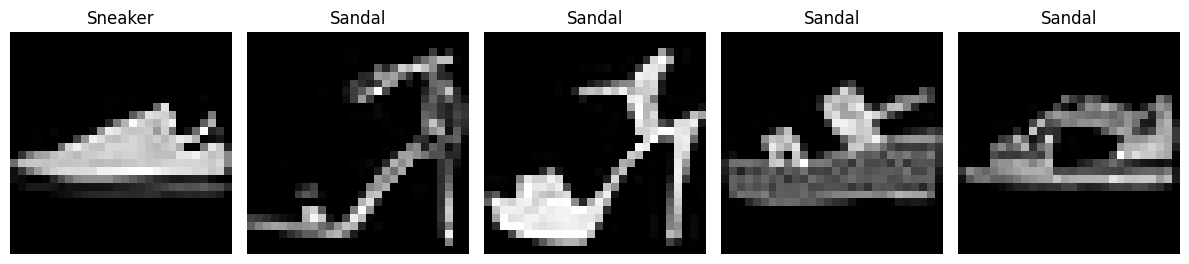

In [3]:



x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)


class_names = ["Sandal", "Sneaker"]

plt.figure(figsize=(12, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(16, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(32, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])


model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,465 (119.00 KB)

 Trainable params: 30,465 (119.00 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:



model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/8
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.9269 - loss: 0.1896 - val_accuracy: 0.9629 - val_loss: 0.1104
Epoch 2/8
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9696 - loss: 0.0880 - val_accuracy: 0.9725 - val_loss: 0.0776
Epoch 3/8
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9757 - loss: 0.0716 - val_accuracy: 0.9729 - val_loss: 0.0736
Epoch 4/8
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9828 - loss: 0.0509 - val_accuracy: 0.9787 - val_loss: 0.0550
Epoch 5/8
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9864 - loss: 0.0413 - val_accuracy: 0.9825 - val_loss: 0.0480
Epoch 6/8
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.9893 - loss: 0.0324 - val_accuracy: 0.9771 - val_loss: 0.0618
Epoch 7/8
300/300 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.9895 - loss: 0.0318 - val_accuracy: 0.9862 - val_loss: 0.0393
Epoch 8/8
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9919 - loss: 0.0238 - val_accuracy: 0

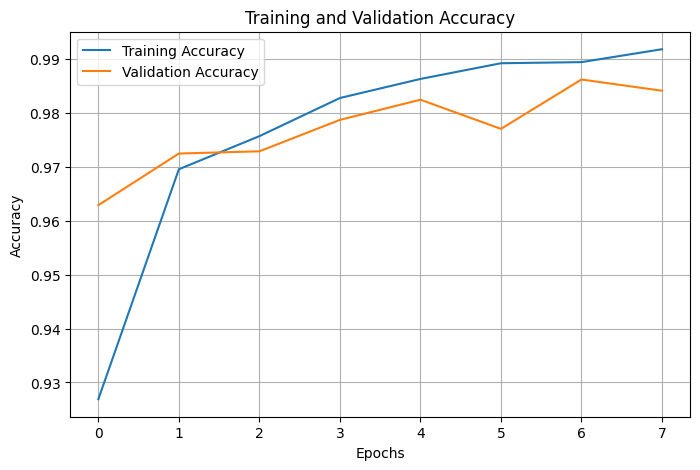

In [6]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


In [7]:


test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


y_prob = model.predict(x_test, verbose=0)


y_pred = (y_prob >= 0.5).astype(int).flatten()


cm = tf.math.confusion_matrix(
    y_test,
    y_pred,
    num_classes=2
)

print("\nConfusion Matrix:")
print(cm.numpy())


Test Loss: 0.03743506968021393
Test Accuracy: 0.9869999885559082

Confusion Matrix:
[[984  16]
 [ 10 990]]


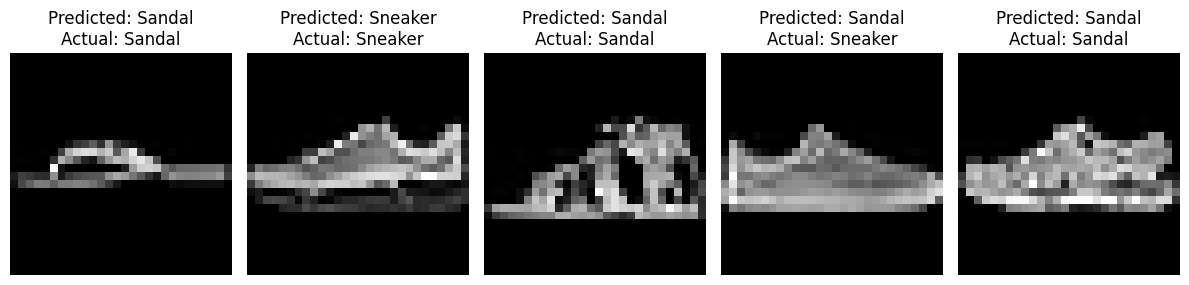

In [8]:


plt.figure(figsize=(12, 4))

for i in range(5):

    predicted_label = int(y_pred[i])
    actual_label = int(y_test[i])

    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")

    plt.title(
        f"Predicted: {class_names[predicted_label]}\n"
        f"Actual: {class_names[actual_label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:

print("Experiment completed successfully!")
print("Task: Sandal vs Sneaker Classification")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("CNN model trained and evaluated successfully.")


Experiment completed successfully!
Task: Sandal vs Sneaker Classification
Test Accuracy: 98.70%
CNN model trained and evaluated successfully.
